# Customer EDA and Target Analysis

## Goal

Describe cleaned customer data, its quality, and patterns associated with conversion before modeling.

## Business question

Before a campaign, which records have higher observed purchase rates? This notebook is descriptive; it does not establish cause and effect.

## Scope and decisions

- Target: `conversion`.
- Pre-campaign attributes describe customers before treatment.
- `visit`, `conversion`, and `spend` are post-campaign outcomes.
- `segment` is campaign assignment and is reviewed separately.
- Keep all rows and the repeat audit flag; no customer ID is available.
- Keep plausible extremes. IQR flags do not automatically mean errors.
- Report row-level patterns, not unique-customer or causal claims.
- Use NumPy and pandas for analysis; use Matplotlib and Seaborn for charts.

## Dataset and source

This analysis uses the cleaned Hillstrom MineThatData email marketing data. Historical attributes precede the campaign; outcomes follow it. Source: https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html.

## Setup and chart style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

BLUE = "#4C78A8"
ORANGE = "#D9825B"
SLATE = "#8493A3"
GRID = "#E4E8EC"

## 1. Load the prepared data

Load the cleaned CSV so this notebook runs independently of Notebook 01.

In [2]:
data = pd.read_csv("../Data-raw/Cleaned/hillstrom_customers_cleaned.csv")

## 2. Check structure and quality

Review size, columns, types, missing values, duplicate flags, binary domains, and outcome consistency.

In [3]:
text_columns = data.select_dtypes(include=["object", "string"]).columns

blank_counts = data[text_columns].apply(
    lambda column: column.str.strip().eq("").sum())

print("Rows:", f"{data.shape[0]:,}")
print("Columns:", data.shape[1])
print("Column names:")
print(data.columns.to_list())
print("\nData types:")
print(data.dtypes.to_string())
print("\nMissing cells:", int(data.isna().sum().sum()))
print("\nBlank Text:\n", blank_counts)


Rows: 64,000
Columns: 13
Column names:
['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend', 'is_exact_repeat_after_first']

Data types:
recency                          int64
history_segment                    str
history                        float64
mens                             int64
womens                           int64
zip_code                           str
newbie                           int64
channel                            str
segment                            str
visit                            int64
conversion                       int64
spend                          float64
is_exact_repeat_after_first       bool

Missing cells: 0

Blank Text:
 history_segment    0
zip_code           0
channel            0
segment            0
dtype: int64


In [4]:
source_columns = data.drop(columns=["is_exact_repeat_after_first"])

print("Flagged repeated rows after the first occurrence:", int(data["is_exact_repeat_after_first"].sum()))
print("Repeated rows after the first occurrence, recalculated:", int(source_columns.duplicated().sum()))
print("Rows belonging to repeated groups:", int(source_columns.duplicated(keep=False).sum()))

Flagged repeated rows after the first occurrence: 6562
Repeated rows after the first occurrence, recalculated: 6562
Rows belonging to repeated groups: 7634


In [5]:
binary_columns = ["mens", "womens", "newbie", "visit", "conversion"]
invalid_binary_values = int((~data[binary_columns].isin([0, 1])).sum().sum())

print("Invalid values across binary columns:", invalid_binary_values)
print("Conversions without a recorded visit:", int(((data["conversion"] == 1) & (data["visit"] == 0)).sum()))
print("Positive spend without conversion:", int(((data["spend"] > 0) & (data["conversion"] == 0)).sum()))
print("Conversions without positive spend:", int(((data["conversion"] == 1) & (data["spend"] <= 0)).sum()))

Invalid values across binary columns: 0
Conversions without a recorded visit: 0
Positive spend without conversion: 0
Conversions without positive spend: 0


## 3. Analyze the target

Compare buyer and non-buyer counts, conversion rate, and the always-negative baseline.

In [6]:
conversion_counts = data["conversion"].value_counts().sort_index()
conversion_shares = data["conversion"].value_counts(normalize=True).sort_index().mul(100)

print("Conversion counts:")
print(conversion_counts.to_string())
print("\nConversion shares (%):")
print(conversion_shares.round(2).to_string())
print("\nOverall conversion rate (%):", round(data["conversion"].mean() * 100, 2))
print("Always-negative baseline accuracy (%):", round((conversion_counts.loc[0] / len(data)) * 100, 2))
print("Buyers found by the always-negative baseline:", 0)

Conversion counts:
conversion
0    63422
1      578

Conversion shares (%):
conversion
0    99.1
1     0.9

Overall conversion rate (%): 0.9
Always-negative baseline accuracy (%): 99.1
Buyers found by the always-negative baseline: 0


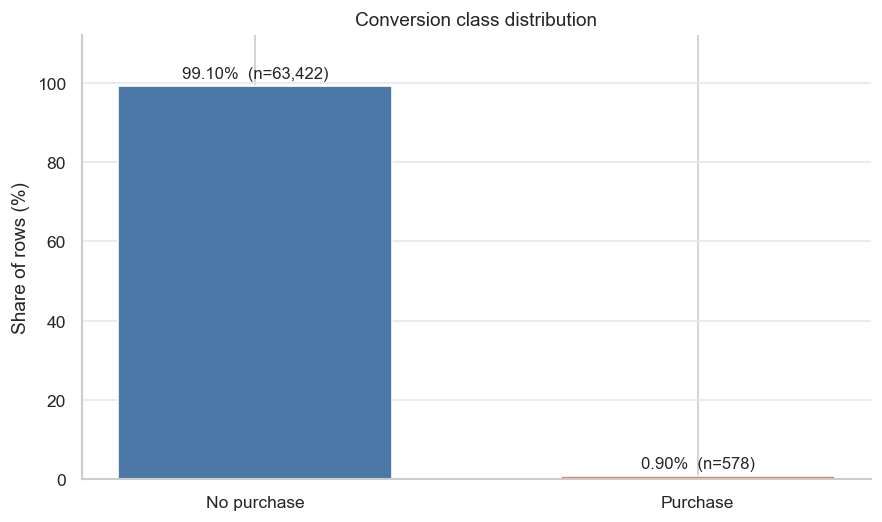

In [7]:
class_counts = conversion_counts.reindex([0, 1])
class_shares = conversion_shares.reindex([0, 1])
class_labels = ["No purchase", "Purchase"]
class_colors = [BLUE, ORANGE]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(class_labels, class_shares.values, color=class_colors, width=0.62)
for bar, count, share in zip(bars, class_counts.values, class_shares.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
            f"{share:.2f}%  (n={count:,})", ha="center", va="bottom", fontsize=10)
ax.set_title("Conversion class distribution")
ax.set_ylabel("Share of rows (%)")
ax.set_ylim(0, 112)
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

The always-negative baseline is about 99.1% accurate but finds no buyers. Accuracy alone is not useful for this imbalanced targeting problem.

## 4. Review numerical distributions

Compare center, spread, range, quartiles, and skewness for `recency` and `history`.

In [8]:
for column in ["recency", "history"]:
    print(f"\n{column} summary:")
    print(data[column].describe().round(2).to_string())
    print("Skewness:", round(data[column].skew(), 3))


recency summary:
count    64000.00
mean         5.76
std          3.51
min          1.00
25%          2.00
50%          6.00
75%          9.00
max         12.00
Skewness: 0.139

history summary:
count    64000.00
mean       242.09
std        256.16
min         29.99
25%         64.66
50%        158.11
75%        325.66
max       3345.93
Skewness: 2.424


In [9]:
print("Recency counts by month:")
print(data["recency"].value_counts().sort_index().to_string())

Recency counts by month:
recency
1     8952
2     7537
3     5904
4     5077
5     4510
6     4605
7     4078
8     3495
9     6441
10    7565
11    3504
12    2332


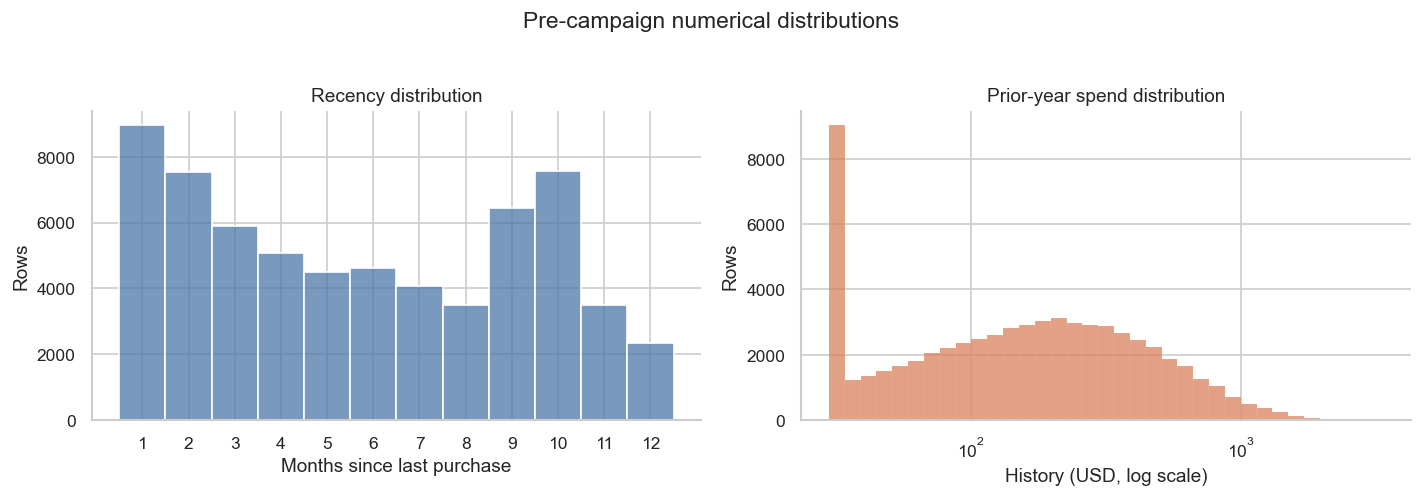

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=data, x="recency", bins=np.arange(0.5, 12.6, 1),
             color=BLUE, ax=axes[0])
axes[0].set_title("Recency distribution")
axes[0].set_xlabel("Months since last purchase")
axes[0].set_ylabel("Rows")
axes[0].set_xticks(range(1, 13))

history_bins = np.logspace(np.log10(data["history"].min()),np.log10(data["history"].max()),36)

sns.histplot(data=data, x="history", bins=history_bins, color=ORANGE, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Prior-year spend distribution")
axes[1].set_xlabel("History (USD, log scale)")
axes[1].set_ylabel("Rows")

fig.suptitle("Pre-campaign numerical distributions", y=1.03)
fig.tight_layout()
plt.show()

### Conversion rate by recency

The line shows the observed rate by months since the last purchase; the dashed line marks the overall rate.

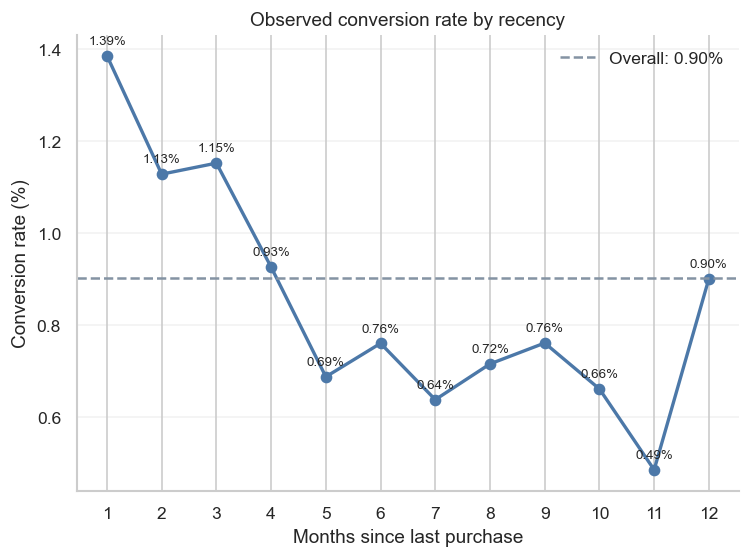

In [11]:
recency_rates = data.groupby("recency")["conversion"].mean().mul(100)
overall_rate = data["conversion"].mean() * 100

fig, ax = plt.subplots()
ax.plot(recency_rates.index, recency_rates.values, marker="o", color=BLUE, linewidth=2)
ax.axhline(overall_rate, color=SLATE, linestyle="--", label=f"Overall: {overall_rate:.2f}%")
for month, rate in recency_rates.items():
    ax.annotate(f"{rate:.2f}%", (month, rate), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.set_title("Observed conversion rate by recency")
ax.set_xlabel("Months since last purchase")
ax.set_ylabel("Conversion rate (%)")
ax.set_xticks(recency_rates.index)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

`history` is the actual amount spent in the previous year, not an average. Its mean is higher than its median, indicating right skew.

## 5. Review spend

`spend` is measured after the campaign. Describe its zero mass and positive values, but do not use it as a pre-campaign feature.

In [12]:
zero_spend_count = int(data["spend"].eq(0).sum())
positive_spend = data.loc[data["spend"] > 0, "spend"]

print("Zero-spend rows:", f"{zero_spend_count:,}")
print("Zero-spend share (%):", round(data["spend"].eq(0).mean() * 100, 2))
print("Positive-spend rows:", f"{len(positive_spend):,}")
print("\nAll-row spend summary:")
print(data["spend"].describe().round(2).to_string())
print("\nPositive-spend summary:")
print(positive_spend.describe().round(2).to_string())
print("Positive-spend skewness:", round(positive_spend.skew(), 3))

Zero-spend rows: 63,422
Zero-spend share (%): 99.1
Positive-spend rows: 578

All-row spend summary:
count    64000.00
mean         1.05
std         15.04
min          0.00
25%          0.00
50%          0.00
75%          0.00
max        499.00

Positive-spend summary:
count    578.00
mean     116.36
std      107.87
min       29.99
25%       32.27
50%       80.80
75%      153.35
max      499.00
Positive-spend skewness: 1.761


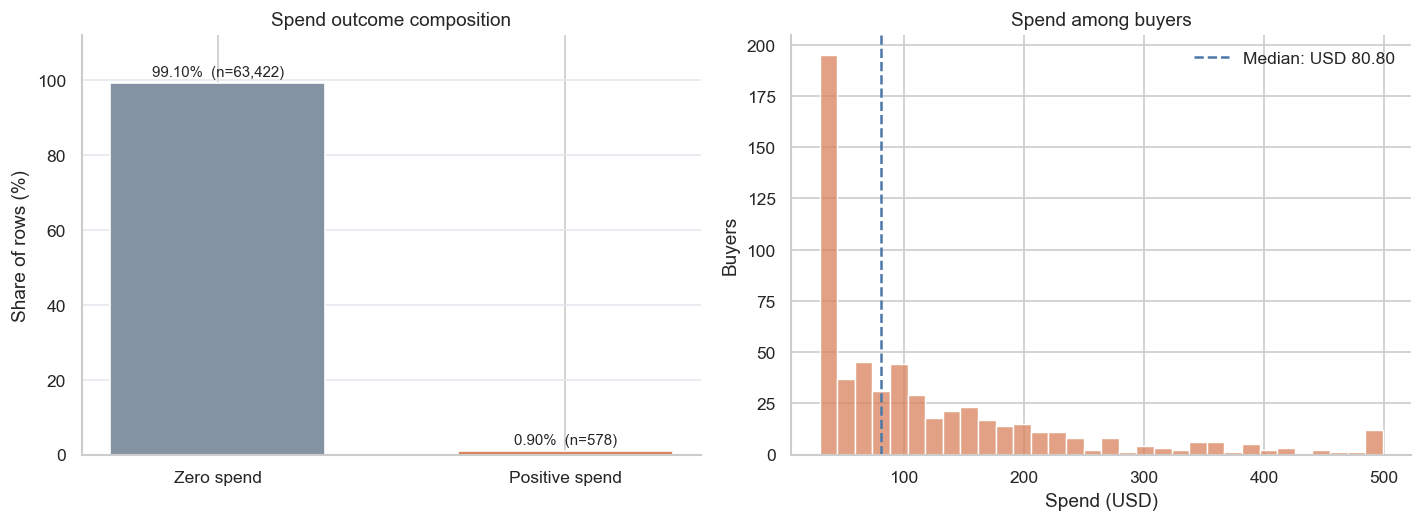

In [13]:
spend_status_counts = np.array([zero_spend_count, len(positive_spend)])
spend_status_shares = spend_status_counts / len(data) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
status_labels = ["Zero spend", "Positive spend"]
status_colors = [SLATE, ORANGE]
bars = axes[0].bar(status_labels, spend_status_shares, color=status_colors, width=0.62)
for bar, count, share in zip(bars, spend_status_counts, spend_status_shares):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2,
                 f"{share:.2f}%  (n={count:,})", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Spend outcome composition")
axes[0].set_ylabel("Share of rows (%)")
axes[0].set_ylim(0, 112)
axes[0].set_axisbelow(True)
axes[0].grid(axis="y", color=GRID)
sns.despine(ax=axes[0])

sns.histplot(x=positive_spend, bins=32, color=ORANGE, ax=axes[1])
axes[1].axvline(positive_spend.median(), color=BLUE, linestyle="--",
                linewidth=1.5, label=f"Median: USD {positive_spend.median():.2f}")
axes[1].set_title("Spend among buyers")
axes[1].set_xlabel("Spend (USD)")
axes[1].set_ylabel("Buyers")
axes[1].legend(frameon=False)

fig.tight_layout()
plt.show()

### Spend among converters\n\nThis box plot uses positive spend only. The dashed line marks the positive-spend IQR review cutoff.

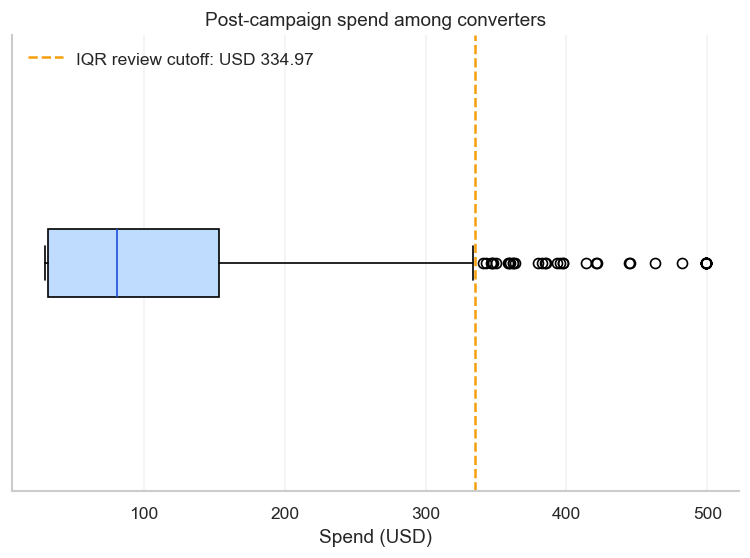

In [14]:
spend_q1, spend_q3 = np.percentile(positive_spend, [25, 75])
spend_iqr_cutoff = spend_q3 + 1.5 * (spend_q3 - spend_q1)

fig, ax = plt.subplots()
box = ax.boxplot(positive_spend, vert=False, patch_artist=True)
box["boxes"][0].set_facecolor("#BFDBFE")
box["medians"][0].set_color("#1D4ED8")
ax.axvline(spend_iqr_cutoff, color="#F59E0B", linestyle="--", label=f"IQR review cutoff: USD {spend_iqr_cutoff:.2f}")
ax.set_title("Post-campaign spend among converters")
ax.set_xlabel("Spend (USD)")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

All positive-spend rows are conversions, and all conversions have positive spend. This outcome relationship creates leakage if used for pre-campaign prediction.

## 6. Review binary and categorical distributions

Check the balance of prior product purchases, customer status, channel, ZIP group, history bands, and campaign assignment.

In [15]:
for column in ["mens", "womens", "newbie", "visit", "conversion"]:
    counts = data[column].value_counts().sort_index()
    shares = data[column].value_counts(normalize=True).sort_index().mul(100)
    print(f"\n{column}:")
    for value in counts.index:
        print(f"{value}: {counts.loc[value]:,} rows ({shares.loc[value]:.2f}%)")


mens:
0: 28,734 rows (44.90%)
1: 35,266 rows (55.10%)

womens:
0: 28,818 rows (45.03%)
1: 35,182 rows (54.97%)

newbie:
0: 31,856 rows (49.78%)
1: 32,144 rows (50.22%)

visit:
0: 54,606 rows (85.32%)
1: 9,394 rows (14.68%)

conversion:
0: 63,422 rows (99.10%)
1: 578 rows (0.90%)


In [16]:
for column in ["history_segment", "zip_code", "channel", "segment"]:
    counts = data[column].value_counts().sort_index()
    shares = data[column].value_counts(normalize=True).sort_index().mul(100)
    print(f"\n{column}:")
    for value in counts.index:
        print(f"{value}: {counts.loc[value]:,} rows ({shares.loc[value]:.2f}%)")


history_segment:
1) $0 - $100: 22,970 rows (35.89%)
2) $100 - $200: 14,254 rows (22.27%)
3) $200 - $350: 12,289 rows (19.20%)
4) $350 - $500: 6,409 rows (10.01%)
5) $500 - $750: 4,911 rows (7.67%)
6) $750 - $1,000: 1,859 rows (2.90%)
7) $1,000 +: 1,308 rows (2.04%)

zip_code:
Rural: 9,563 rows (14.94%)
Suburban: 28,776 rows (44.96%)
Urban: 25,661 rows (40.10%)

channel:
Multichannel: 7,762 rows (12.13%)
Phone: 28,021 rows (43.78%)
Web: 28,217 rows (44.09%)

segment:
Mens E-Mail: 21,307 rows (33.29%)
No E-Mail: 21,306 rows (33.29%)
Womens E-Mail: 21,387 rows (33.42%)


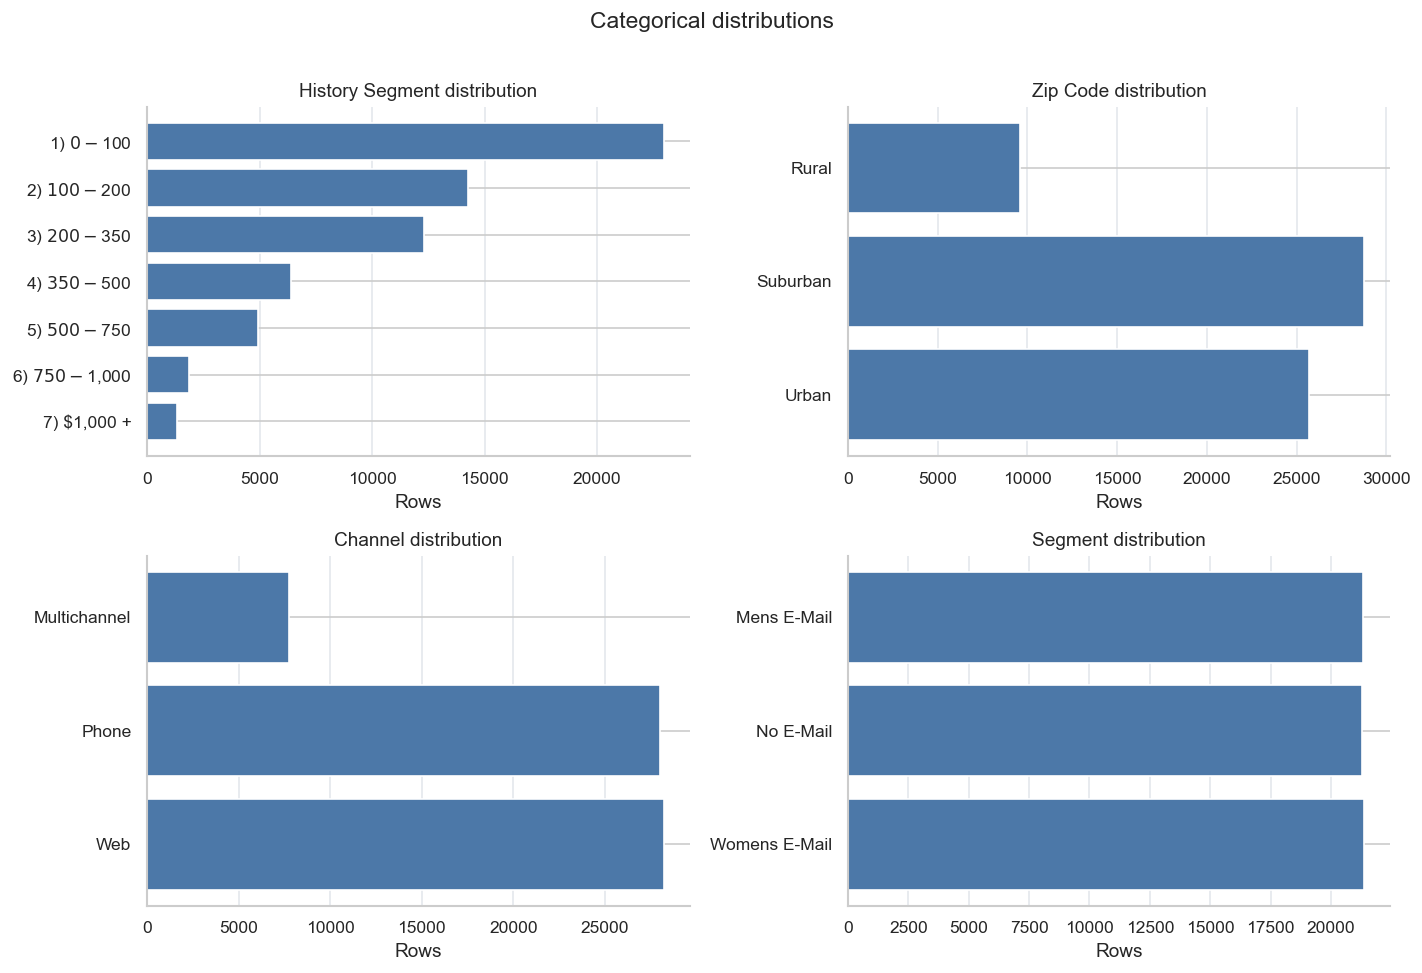

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
distribution_columns = ["history_segment", "zip_code", "channel", "segment"]

for ax, column in zip(axes.flat, distribution_columns):
    counts = data[column].value_counts().sort_index()
    ax.barh(counts.index.astype(str), counts.values, color=BLUE)
    ax.invert_yaxis()
    ax.set_title(f"{column.replace('_', ' ').title()} distribution")
    ax.set_xlabel("Rows")
    ax.set_ylabel("")
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

fig.suptitle("Categorical distributions", y=1.01)
fig.tight_layout()
plt.show()

`mens` and `womens` indicate past product purchases, not customer gender, and are not mutually exclusive. `segment` is campaign assignment.

## 7. Review outliers without deleting rows

Apply IQR to `recency`, `history`, and `spend`; record bounds and flagged counts.

In [18]:
for column in ["recency", "history"]:
    q1, q3 = np.percentile(data[column], [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    flagged_count = int(((data[column] < lower_bound) | (data[column] > upper_bound)).sum())
    print(f"{column}: Q1={q1:.2f}, Q3={q3:.2f}, upper={upper_bound:.2f}, flagged={flagged_count:,}")

q1, q3 = np.percentile(data["spend"], [25, 75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
flagged_count = int((data["spend"] > upper_bound).sum())
print(f"spend across all rows: Q1={q1:.2f}, Q3={q3:.2f}, upper={upper_bound:.2f}, flagged={flagged_count:,}")

q1, q3 = np.percentile(positive_spend, [25, 75])
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
flagged_count = int((positive_spend > upper_bound).sum())
print(f"positive spend only: Q1={q1:.2f}, Q3={q3:.2f}, upper={upper_bound:.2f}, flagged={flagged_count:,}")
print("Rows with spend equal to USD 499:", int(data["spend"].eq(499).sum()))


recency: Q1=2.00, Q3=9.00, upper=19.50, flagged=0
history: Q1=64.66, Q3=325.66, upper=717.15, flagged=3,593
spend across all rows: Q1=0.00, Q3=0.00, upper=0.00, flagged=578
positive spend only: Q1=32.27, Q3=153.35, upper=334.97, flagged=39
Rows with spend equal to USD 499: 12


The all-row IQR flags every positive `spend` value because its third quartile is zero. Among positive spenders, 39 values exceed USD 334.97; 12 equal USD 499. Keep them and treat possible top-coding as unverified.

## 8. Compare conversion by group

Show each group's row count, purchases, and conversion rate. Include denominators because purchases are rare.

In [19]:
for column in ["recency", "history_segment", "zip_code", "channel", "newbie", "mens", "womens", "segment"]:
    print(f"\n{column}:")
    grouped_conversion = data.groupby(column)["conversion"]
    for value, outcomes in grouped_conversion:
        rate = outcomes.mean() * 100
        print(f"{value}: rows={outcomes.size:,}, conversions={int(outcomes.sum()):,}, rate={rate:.2f}%")


recency:
1: rows=8,952, conversions=124, rate=1.39%
2: rows=7,537, conversions=85, rate=1.13%
3: rows=5,904, conversions=68, rate=1.15%
4: rows=5,077, conversions=47, rate=0.93%
5: rows=4,510, conversions=31, rate=0.69%
6: rows=4,605, conversions=35, rate=0.76%
7: rows=4,078, conversions=26, rate=0.64%
8: rows=3,495, conversions=25, rate=0.72%
9: rows=6,441, conversions=49, rate=0.76%
10: rows=7,565, conversions=50, rate=0.66%
11: rows=3,504, conversions=17, rate=0.49%
12: rows=2,332, conversions=21, rate=0.90%

history_segment:
1) $0 - $100: rows=22,970, conversions=164, rate=0.71%
2) $100 - $200: rows=14,254, conversions=99, rate=0.69%
3) $200 - $350: rows=12,289, conversions=117, rate=0.95%
4) $350 - $500: rows=6,409, conversions=86, rate=1.34%
5) $500 - $750: rows=4,911, conversions=57, rate=1.16%
6) $750 - $1,000: rows=1,859, conversions=27, rate=1.45%
7) $1,000 +: rows=1,308, conversions=28, rate=2.14%

zip_code:
Rural: rows=9,563, conversions=107, rate=1.12%
Suburban: rows=28,7

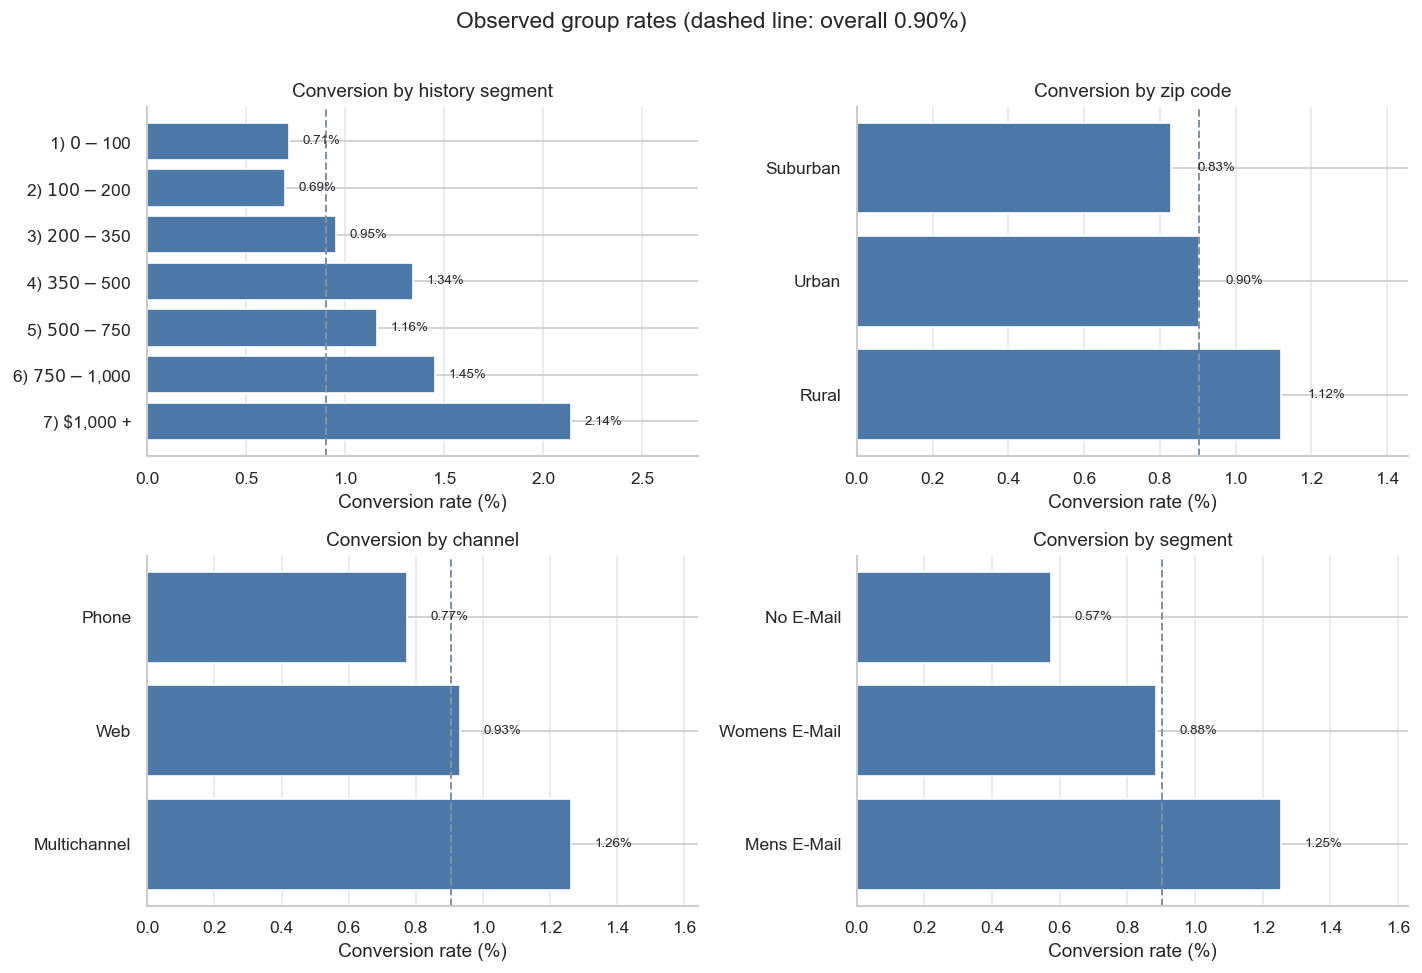

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rate_columns = ["history_segment", "zip_code", "channel", "segment"]

for ax, column in zip(axes.flat, rate_columns):
    rates = data.groupby(column)["conversion"].mean().mul(100)
    if column != "history_segment":
        rates = rates.sort_values()
    labels = rates.index.astype(str)
    ax.barh(labels, rates.values, color=BLUE)
    ax.axvline(overall_rate, color=SLATE, linestyle="--", linewidth=1.2)
    for position, value in enumerate(rates.values):
        ax.text(value + 0.07, position, f"{value:.2f}%", va="center", fontsize=8)
    ax.set_xlim(0, max(rates.max() * 1.3, overall_rate * 1.3))
    ax.invert_yaxis()
    ax.set_title(f"Conversion by {column.replace('_', ' ')}")
    ax.set_xlabel("Conversion rate (%)")
    ax.set_ylabel("")
    ax.grid(axis="x", color=GRID)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

fig.suptitle(f"Observed group rates (dashed line: overall {overall_rate:.2f}%)", y=1.01)
fig.tight_layout()
plt.show()

These are descriptive row-level rates. Do not claim campaign impact from this predictive analysis. `segment` is not a pre-campaign targeting input.

## 9. Review correlations and leakage

Inspect correlations among pre-campaign features separately from post-campaign outcomes.

In [21]:
pre_campaign_features = ["recency", "history", "mens", "womens", "newbie"]

print("Pairwise correlations among pre-campaign numerical features:")
for first_index, first_feature in enumerate(pre_campaign_features):
    for second_feature in pre_campaign_features[first_index + 1:]:
        correlation = data[first_feature].corr(data[second_feature])
        print(f"{first_feature} and {second_feature}: {correlation:.3f}")

print("\nCorrelation with conversion, for descriptive review only:")
for feature in pre_campaign_features:
    print(f"{feature}: {data[feature].corr(data['conversion']):.3f}")

print("\nPost-campaign outcome correlations:")
print("spend and conversion:", round(data["spend"].corr(data["conversion"]), 3))
print("visit and conversion:", round(data["visit"].corr(data["conversion"]), 3))

Pairwise correlations among pre-campaign numerical features:
recency and history: -0.247
recency and mens: -0.031
recency and womens: -0.027
recency and newbie: -0.052
history and mens: 0.113
history and womens: 0.115
history and newbie: 0.223
mens and womens: -0.817
mens and newbie: 0.021
womens and newbie: 0.021

Correlation with conversion, for descriptive review only:
recency: -0.024
history: 0.029
mens: 0.002
womens: 0.013
newbie: -0.011

Post-campaign outcome correlations:
spend and conversion: 0.732
visit and conversion: 0.23


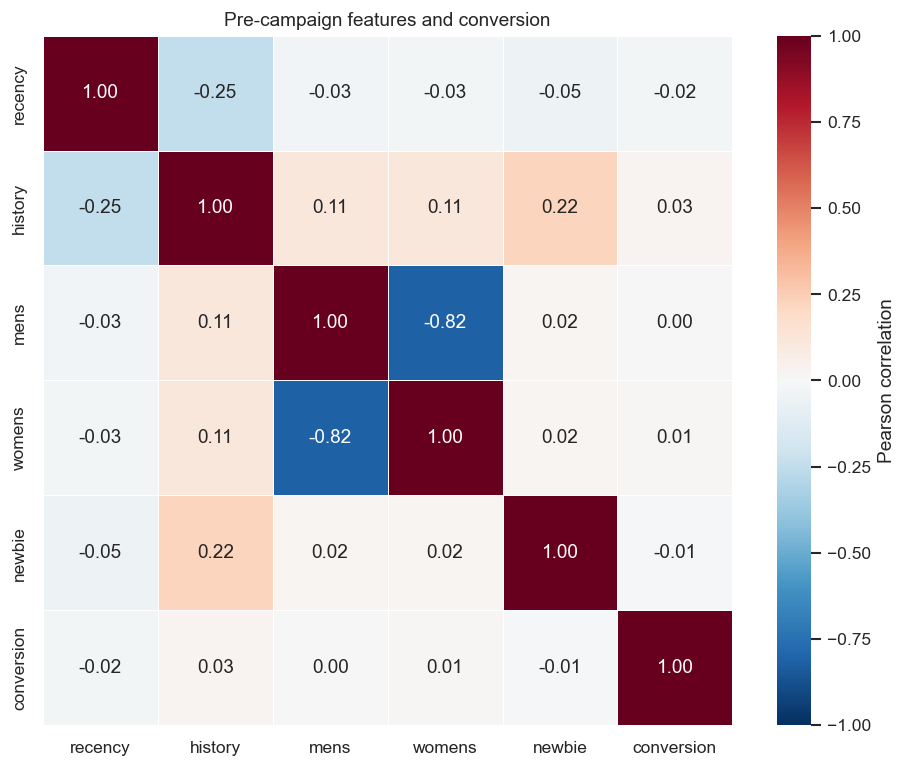

In [22]:
heatmap_features = pre_campaign_features + ["conversion"]
correlation_matrix = data[heatmap_features].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Pre-campaign features and conversion")
ax.set_xlabel("")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

The negative `mens`-`womens` correlation is association, not causation. The strong `spend`-`conversion` relationship is expected because spend is post-campaign and zero for non-buyers.

## 10. EDA findings

- The file has 64,000 rows, 13 columns, and 6,562 later exact repeats, retained because no customer ID is available.
- There are 578 conversions (0.90%). The always-negative rule has 99.10% accuracy and finds zero buyers.
- `history` is right-skewed: mean USD 242, median USD 158, maximum USD 3,346.
- `spend` is zero in 99.10% of rows; its 578 positive values match the 578 conversions.
- Recency months 1-3 have a combined 1.24% conversion rate versus 0.90% overall; rates are not monotonic across all months.
- The `$1,000+` history band has the highest observed rate: 28 of 1,308 rows (2.14%).
- Rates: Multichannel 1.26%, Phone 0.77%, Web 0.93%; Rural 1.12%, Suburban 0.83%, Urban 0.90%.
- Campaign assignment rates: Mens E-Mail 1.25%, Womens E-Mail 0.88%, No E-Mail 0.57%. These are descriptive, not causal.

## 11. Quality and modeling implications

- No missing cells or invalid binary values were found; Notebook 01 checked types, categories, logic, and history bands.
- Keep valid extremes. The spend IQR flags reflect zero inflation and high positive purchases.
- Counts are row-level; repeated records remain and customer uniqueness cannot be verified.
- Exclude `visit`, `conversion`, `spend`, and the repeat flag from pre-campaign model inputs. Handle `segment` as a separate campaign comparison.
- Evaluate imbalance with precision, recall, F1, ROC-AUC, PR-AUC, and a confusion matrix; do not select by accuracy alone.
- Prediction does not establish campaign lift or causality.

## 12. Next step

Define eligible pre-campaign features, then create a stratified train/test split. Fit learned preprocessing on training data only.